# CIFAR-10 Image Classification

## Part 1: Load and understand CIFAR-10

### Import the libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

import tensorflow as tf 
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV2, mobilenet_v2
from tensorflow.keras.layers import (
Input,Conv2D,MaxPooling2D,GlobalAveragePooling2D,Dense,Dropout,BatchNormalization)

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
classification_report,confusion_matrix,ConfusionMatrixDisplay)

### Load the dataset

In [2]:
(x_train_full,y_train_full),(x_test,y_test) = cifar10.load_data()

print(f'Training images: {x_train_full.shape}')
print(f'Training labels: {y_train_full.shape}')

print(f'Test images: {x_test.shape}')
print(f'Test labels: {y_test.shape}')

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


### Understand the image and label shapes

In [3]:
print(f'One Image Shape : {x_train_full[0].shape}')
print(f'One Image dtype : {x_train_full[0].dtype}')

print(f'First 10 Labels: \n{y_train_full[:10].flatten()}')

print(f'Minimum pixel value: {x_train_full.min()}')
print(f'Maximum pixel value: {x_train_full.max()}')

One Image Shape : (32, 32, 3)
One Image dtype : uint8
First 10 Labels: 
[6 9 9 4 1 1 2 7 8 3]
Minimum pixel value: 0
Maximum pixel value: 255


### Map numbers to class names

In [4]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

for i , name in enumerate(class_names):
    print(i ,"->" , name)

0 -> airplane
1 -> automobile
2 -> bird
3 -> cat
4 -> deer
5 -> dog
6 -> frog
7 -> horse
8 -> ship
9 -> truck


This mapping is important because the model predicts numerical class scores, but we want to interpret predictions as meaningful categories.

### Visualize the images

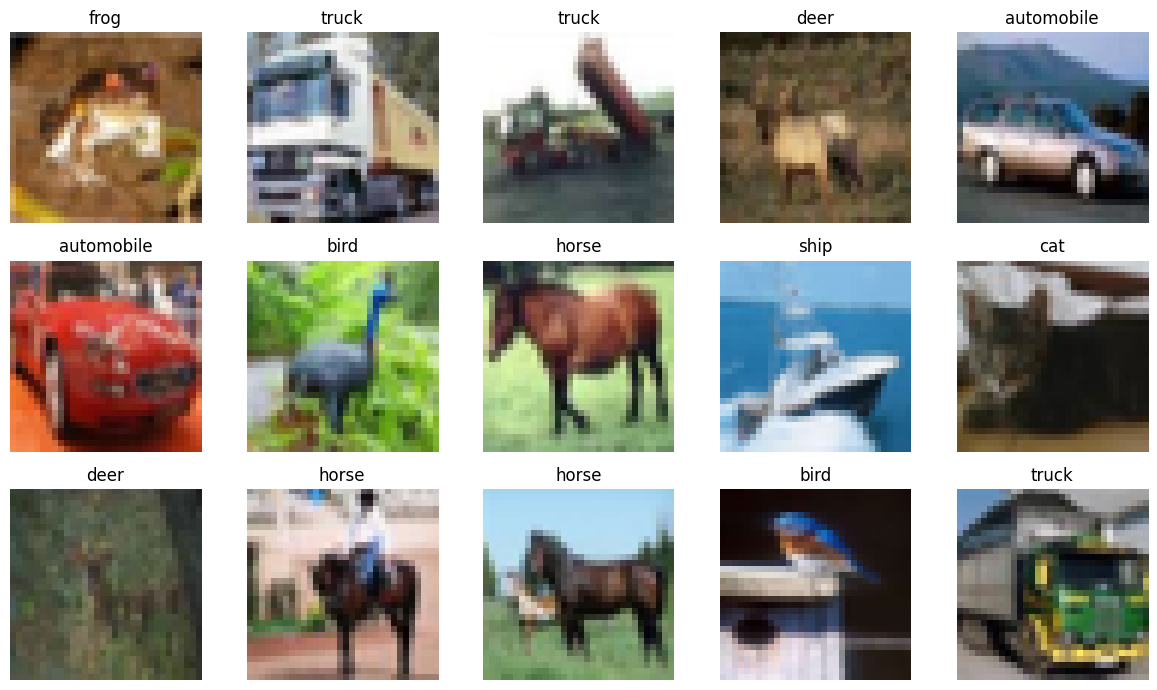

In [5]:
plt.figure(figsize= (12,7))

for i in range(15):
    plt.subplot(3,5,i+1)
    plt.imshow(x_train_full[i])
    
    label = int(y_train_full[i,0])
    plt.title(class_names[label])

    plt.axis('off')

plt.tight_layout()
plt.show()

### Check class distribution

In [6]:
unique_classes ,class_count = np.unique(y_train_full, return_counts=True)

for class_id , count in zip(unique_classes,class_count): 
    print(f'{class_names[class_id]}: {count}')

airplane: 5000
automobile: 5000
bird: 5000
cat: 5000
deer: 5000
dog: 5000
frog: 5000
horse: 5000
ship: 5000
truck: 5000


**Insight**

CIFAR-10 is balanced: each class has 5,000 training images. This gives us a useful baseline: random guessing across ten equally likely classes would achieve about 10% accuracy.

## Part 2: Prepare the data for deep learning

### Create training and validation sets

We have 50,000 training images and 10,000 test images. We'll reserve 5,000 images from the training set for validation.

In [7]:
x_train,x_val,y_train,y_val = train_test_split(
    x_train_full, 
    y_train_full,  
    test_size=0.1,
    random_state=42,
    stratify= y_train_full.flatten()
)

print(f'Training: {x_train.shape , y_train.shape}')
print(f'Validation: {x_val.shape , y_val.shape}')
print(f'Test: {x_test.shape , y_test.shape}')

Training: ((45000, 32, 32, 3), (45000, 1))
Validation: ((5000, 32, 32, 3), (5000, 1))
Test: ((10000, 32, 32, 3), (10000, 1))


### Normalization

For an image pixel with an RGB value of [255, 128, 0], dividing by 255 gives approximately [1.0, 0.502, 0.0], Range(0-1)

In [8]:
sample_pixel = x_train[0, 0, 0]
normalized_pixel = sample_pixel.astype("float32") / 255.0

print(f'Original RGB pixel: {sample_pixel}')
print(f'Normalized RGB pixel: {normalized_pixel}')
print(f'Original data type: {x_train.dtype}')

Original RGB pixel: [31 47 21]
Normalized RGB pixel: [0.12156863 0.18431373 0.08235294]
Original data type: uint8


### Build efficient TensorFlow data pipelines

A data pipeline prepares and feeds batches of images to the model.

Instead of loading every normalized image into memory, we'll normalize each image as TensorFlow processes it.

In [9]:
Batch_Size = 64
Autotune = tf.data.AUTOTUNE 

def preprocess_image(image,label):
    image = tf.cast(image , tf.float32) / 255.0 
    label = tf.cast(tf.squeeze(label) , tf.int32)

    return image , label 


train_ds = (
    tf.data.Dataset.from_tensor_slices((x_train, y_train))
    .shuffle(10000, seed=42)
    .map(preprocess_image, num_parallel_calls=Autotune)
    .batch(Batch_Size)
    .prefetch(Autotune)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((x_val, y_val))
    .map(preprocess_image, num_parallel_calls=Autotune)
    .batch(Batch_Size)
    .prefetch(Autotune)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .map(preprocess_image, num_parallel_calls=Autotune)
    .batch(Batch_Size)
    .prefetch(Autotune)
)

### Verify the pipeline

In [10]:
images, labels = next(iter(train_ds))

print(f'Batch image shape: {images.shape}')
print(f'Batch label shape: {labels.shape}')

print(f'Minimum pixel value: {tf.reduce_min(images).numpy()}')
print(f'Maximum pixel value: {tf.reduce_max(images).numpy()}')

print(f'First 10 labels: {labels[:10].numpy()}')

Batch image shape: (64, 32, 32, 3)
Batch label shape: (64,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
First 10 labels: [2 1 3 5 5 3 0 3 1 3]


## Part 3: Build a CNN from scratch

### Create the CNN model

In [11]:
cnn = Sequential([
    Input(shape= (32,32,3)),

    # Convolution block 1
    Conv2D(32, (3,3) , padding='same' , activation='relu'),
    MaxPooling2D((2,2)),

    # Convolution block 2
    Conv2D(64, (3,3) , padding='same' , activation='relu'),
    MaxPooling2D((2,2)),

    # Convolution block 3
    Conv2D(128, (3,3) , padding='same' , activation='relu'),
    MaxPooling2D((2,2)),

    # Classification
    GlobalAveragePooling2D() ,

    Dense(128 , activation='relu'),
    Dropout(0.3),

    Dense(10, activation='softmax')

])

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

### Compile the model

Creating a model defines its architecture. Compiling it specifies how it will learn.

In [12]:
cnn.compile(
    optimizer= Adam(learning_rate=0.001),
    loss= "sparse_categorical_crossentropy",
    metrics= ["accuracy"]
)

### Train the CNN

We'll use early stopping so training can stop when validation performance stops improving.

In [13]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience= 3,
    restore_best_weights= True
)

history_cnn = cnn.fit(
    train_ds, 
    validation_data = val_ds,
    epochs= 15,
    callbacks=[early_stopping],
    verbose= 1
)

Epoch 1/15


C:\Users\smata\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 40ms/step - accuracy: 0.3113 - loss: 1.8128 - val_accuracy: 0.3940 - val_loss: 1.6222
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 39ms/step - accuracy: 0.4584 - loss: 1.4601 - val_accuracy: 0.5020 - val_loss: 1.3284
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.5237 - loss: 1.3125 - val_accuracy: 0.5626 - val_loss: 1.1833
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 27s 38ms/step - accuracy: 0.5640 - loss: 1.2038 - val_accuracy: 0.6064 - val_loss: 1.0870
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.5969 - loss: 1.1207 - val_accuracy: 0.6164 - val_loss: 1.0543
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.6293 - loss: 1.0416 - val_accuracy: 0.6440 - val_loss: 0.9985
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.6502 - loss: 0.9878 - val_accuracy: 0.6400 - val_loss: 1.0022
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.6695 - loss: 0.9316 - val_accurac

### Plot accuracy and loss

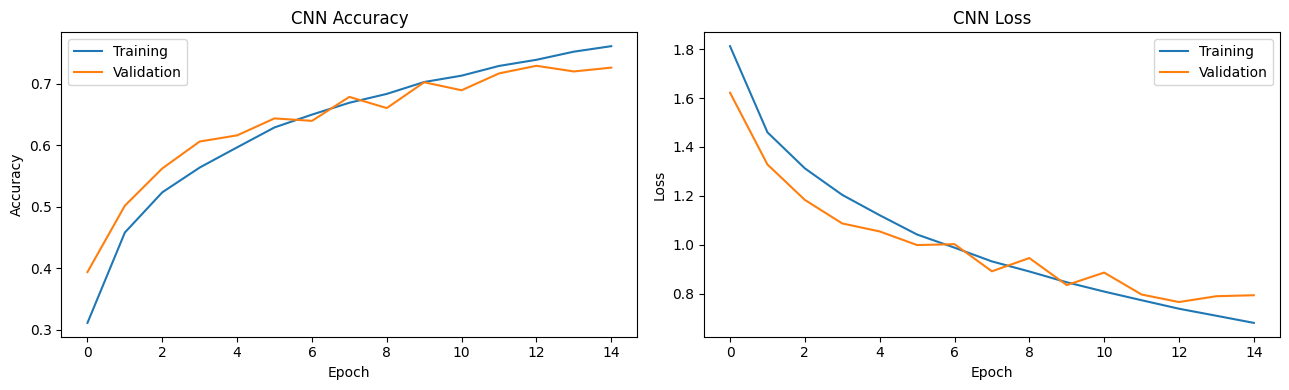

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_cnn.history["accuracy"], label="Training")
axes[0].plot(history_cnn.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_cnn.history["loss"], label="Training")
axes[1].plot(history_cnn.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

**Insight**

The CNN showed consistent learning over 15 epochs, with training accuracy increasing to approximately 75% and validation accuracy reaching approximately 72%. Both training and validation loss decreased substantially, indicating that the model learned meaningful patterns from the CIFAR-10 dataset. However, validation loss fluctuated slightly during the final epochs while training loss continued to decrease, suggesting possible mild overfitting. Early stopping and further regularization experiments may improve generalization. The model's final performance should be confirmed using the independent test set.

In [15]:
test_loss_cnn , test_accuracy_cnn = cnn.evaluate(
    test_ds, verbose = 1
)

print(f'CNN test loss: {test_loss_cnn:.4f}')
print(f'CNN test accuracy: {test_accuracy_cnn:.4f}')
print(f'CNN accuracy: {test_accuracy_cnn * 100:.2f}%')

157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.7286 - loss: 0.7789
CNN test loss: 0.7789
CNN test accuracy: 0.7286
CNN accuracy: 72.86%


## Part 4: Transfer Learning with MobileNetV2

### Prepare images for MobileNetV2

MobileNetV2 expects larger inputs than CIFAR-10's 32 × 32 images. We'll resize them to 96 × 96 as a practical compromise for CPU training.

We will keep the original arrays unchanged and resize images in batches to avoid storing all resized images in memory at once.

MobileNetV2 preprocessing: scale pixels to [-1, 1]

In [16]:
Img_Size = 96 
Batch_Size_TL = 32 

def preprocess_transfer(image,label):
    image = tf.cast(image , tf.float32)
    image = tf.image.resize(image , (Img_Size,Img_Size))
    image = mobilenet_v2.preprocess_input(image)  # Scale pixels to [-1,1]

    label = tf.cast(tf.squeeze(label) , tf.int32)

    return image , label

### Build transfer-learning datasets

In [17]:
train_ds_tl = (
    tf.data.Dataset.from_tensor_slices((x_train,y_train))
    .shuffle(10000,seed = 42)
    .map(preprocess_transfer, num_parallel_calls= Autotune)
    .batch(Batch_Size_TL)
    .prefetch(Autotune)
)

val_ds_tl = (
    tf.data.Dataset.from_tensor_slices((x_val,y_val))
    .map(preprocess_transfer, num_parallel_calls= Autotune)
    .batch(Batch_Size_TL)
    .prefetch(Autotune)
)

test_ds_tl = (
    tf.data.Dataset.from_tensor_slices((x_test,y_test))
    .map(preprocess_transfer, num_parallel_calls= Autotune)
    .batch(Batch_Size_TL)
    .prefetch(Autotune)
)

### Load the pretrained model

In [18]:
base_model = MobileNetV2(
    input_shape= (Img_Size,Img_Size,3),
    include_top= False,
    weights= 'imagenet',
)

print(f'Number of layers: {len(base_model.layers)}')

# Freeze the pretrained layers 
base_model.trainable = False 
print(f'Base model trainable: {base_model.trainable}')

Number of layers: 154
Base model trainable: False


### Add a new classification head

In [19]:
inputs = Input(shape= (Img_Size,Img_Size,3))

x = base_model(inputs , training = False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)

outputs = Dense(10,activation= 'softmax')(x)

transfer_model = tf.keras.Model(inputs= inputs , outputs = outputs)

transfer_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Compile and train the classifier

In [20]:
transfer_model.compile(
    Adam(learning_rate= 0.001),
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

early_stopping_tl = EarlyStopping(
    monitor= 'val_loss',
    patience= 2,
    verbose=1
)

history_tl = transfer_model.fit(
    train_ds_tl,
    validation_data = val_ds_tl,
    epochs= 5,
    callbacks= [early_stopping_tl],
    verbose = 1
)

Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 161s 109ms/step - accuracy: 0.7842 - loss: 0.6468 - val_accuracy: 0.8552 - val_loss: 0.4225
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 153s 109ms/step - accuracy: 0.8341 - loss: 0.4941 - val_accuracy: 0.8622 - val_loss: 0.4049
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 151s 107ms/step - accuracy: 0.8385 - loss: 0.4761 - val_accuracy: 0.8578 - val_loss: 0.4102
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 153s 109ms/step - accuracy: 0.8424 - loss: 0.4659 - val_accuracy: 0.8532 - val_loss: 0.4193
Epoch 4: early stopping


### Evaluate the frozen transfer-learning model

In [21]:
test_loss_tl , test_accuracy_tl = transfer_model.evaluate(
    test_ds_tl, verbose = 1
)

print(f'Transfer-learning test loss: {test_loss_tl:.4f}')
print(f'Transfer-learning test accuracy: {test_accuracy_tl:.4f}')
print(f'Transfer-learning accuracy: {test_accuracy_tl * 100:.2f}%')

313/313 ━━━━━━━━━━━━━━━━━━━━ 31s 100ms/step - accuracy: 0.8499 - loss: 0.4445
Transfer-learning test loss: 0.4445
Transfer-learning test accuracy: 0.8499
Transfer-learning accuracy: 84.99%


## Part 5: Fine-tune MobileNetV2

### Unfreeze selected layers

we'll unfreeze the last 30 layers, while keeping Batch Normalization layers frozen. These upper layers can adapt their learned features to CIFAR-10, while the earlier layers retain their general visual features.

In [22]:
base_model.trainable = True 

for layer in base_model.layers[:-30]:
    layer.train_function = False 

for layer in base_model.layers:
    if isinstance(layer , BatchNormalization):
        layer.trainable = False 

print(f'Total Base Model Layers: {len(base_model.layers)}')
print(f'Trainable base layers: {sum(layer.trainable for layer in base_model.layers)}')

Total Base Model Layers: 154
Trainable base layers: 102


### Recompile with a smaller learning rate

In [23]:
transfer_model.compile(
    Adam(learning_rate= 0.00001),
    loss = 'sparse_categorical_crossentropy',
    metrics=["accuracy"]
)

### Fine-tune the model

In [24]:
early_stopping_ft = EarlyStopping(
    monitor= "val_loss",
    patience= 2,
    restore_best_weights= True
)

history_ft = transfer_model.fit(
    train_ds_tl,
    validation_data= val_ds_tl,
    epochs= 4,
    callbacks= [early_stopping_ft],
    verbose= 1
)

Epoch 1/4
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 367s 248ms/step - accuracy: 0.8916 - loss: 0.3197 - val_accuracy: 0.9052 - val_loss: 0.2690
Epoch 2/4
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 362s 257ms/step - accuracy: 0.9253 - loss: 0.2193 - val_accuracy: 0.9226 - val_loss: 0.2239
Epoch 3/4
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 347s 247ms/step - accuracy: 0.9424 - loss: 0.1652 - val_accuracy: 0.9306 - val_loss: 0.2059
Epoch 4/4
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 340s 242ms/step - accuracy: 0.9574 - loss: 0.1221 - val_accuracy: 0.9342 - val_loss: 0.2018


### Evaluate the fine-tuned model

In [25]:
test_loss_ft , test_accuracy_ft = transfer_model.evaluate(
    test_ds_tl, verbose = 1
)

print(f'Fine-tuned test loss: {test_loss_ft:.4f}')
print(f'Fine-tuned test accuracy: {test_accuracy_ft:.4f}')
print(f'Fine-tuned accuracyy: {test_accuracy_ft * 100:.2f}%')

313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 96ms/step - accuracy: 0.9266 - loss: 0.2292
Fine-tuned test loss: 0.2292
Fine-tuned test accuracy: 0.9266
Fine-tuned accuracyy: 92.66%


### Plot the fine-tuning curves

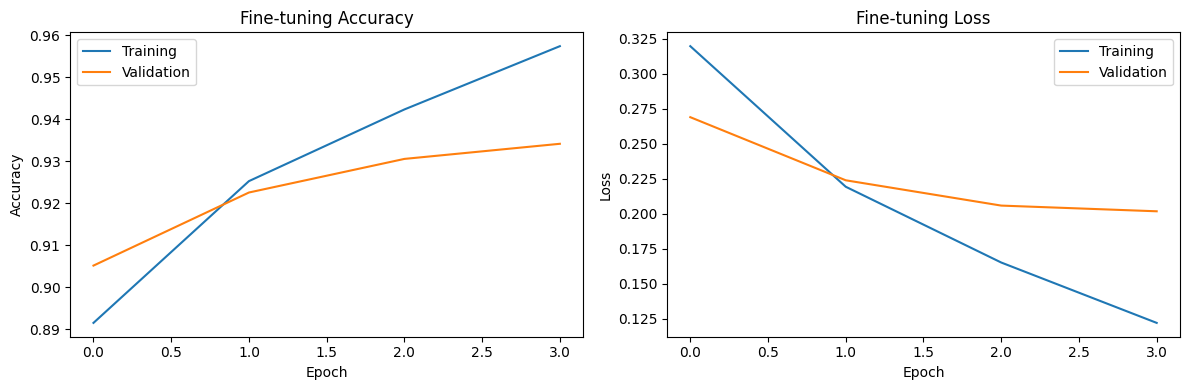

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_ft.history["accuracy"],label="Training")
axes[0].plot(history_ft.history["val_accuracy"],label="Validation")
axes[0].set_title("Fine-tuning Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history_ft.history["loss"],label="Training")
axes[1].plot(history_ft.history["val_loss"],label="Validation")
axes[1].set_title("Fine-tuning Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

## Part 6: Evaluate and compare all three models

### Build the comparison table

In [27]:
comparison = pd.DataFrame({
    
    'Model':[
        "Custom CNN (from scratch)",
        "MobileNetV2 (frozen)",
        "MobileNetV2 (fine-tuned)"
    ], 
    
    "Test Accuracy (%)": [
        test_accuracy_cnn * 100,
        test_accuracy_tl * 100,
        test_accuracy_ft * 100
    ], 

     "Test Loss": [
        test_loss_cnn,
        test_loss_tl,
        test_loss_ft
    ]
})

comparison = comparison.sort_values(
    by = 'Test Accuracy (%)', ascending = False).reset_index(drop = True)

comparison.round(4)

,Model,Test Accuracy (%),Test Loss
0,MobileNetV2 (fine-tuned),92.66,0.2292
1,MobileNetV2 (frozen),84.99,0.4445
2,Custom CNN (from scratch),72.86,0.7789


**Conclusion**

In this experiment, three deep learning approaches were evaluated on the CIFAR-10 image classification dataset: a custom CNN trained from scratch, a frozen MobileNetV2 model, and a fine-tuned MobileNetV2 model.

The custom CNN achieved a test accuracy of 72.86% and a test loss of 0.7789. The frozen MobileNetV2 model achieved 84.99% accuracy and a loss of 0.4445, demonstrating the benefit of using pretrained image features. After fine-tuning selected layers of MobileNetV2, test accuracy increased to 92.66%, while test loss decreased to 0.2292.

The fine-tuned model outperformed the frozen model by 7.67 percentage points and the custom CNN by 19.80 percentage points. These results demonstrate that transfer learning can improve image classification performance by leveraging previously learned features, while fine-tuning can further adapt those features to the target dataset.

Overall, fine-tuned MobileNetV2 achieved the best performance among the evaluated models. However, the comparison should be interpreted in the context of the different architectures, input resolutions, pretrained weights, and training configurations used.


### Visualize the comparison

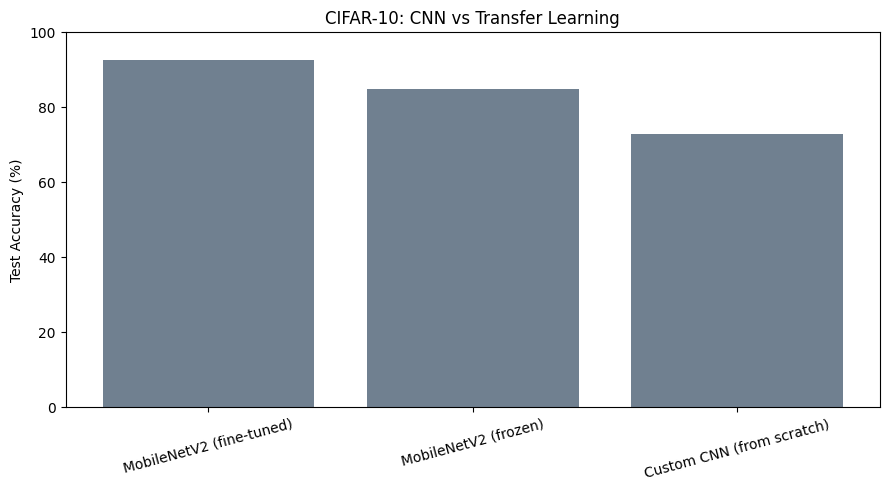

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"],
    color = 'slategray'
)

plt.ylabel("Test Accuracy (%)")
plt.title("CIFAR-10: CNN vs Transfer Learning")

plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Generate predictions for the fine-tuned model

In [29]:
y_true = np.concatenate([
    label.numpy()
    for _,label in test_ds_tl
])

y_prob_ft = transfer_model.predict(test_ds_tl, verbose = 1)

y_pred_ft = np.argmax(y_prob_ft , axis=1)

print(f'True labels shape: {y_true.shape}')
print(f'Predicted labels shape:: {y_pred_ft.shape}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 92ms/step
True labels shape: (10000,)
Predicted labels shape:: (10000,)


### Calculate precision, recall, and F1-score

In [30]:
class_report = classification_report(
    y_true,
    y_pred_ft,
    labels=np.arange(10),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print(class_report)

              precision    recall  f1-score   support

    airplane     0.9208    0.9300    0.9254      1000
  automobile     0.9628    0.9580    0.9604      1000
        bird     0.9130    0.9450    0.9287      1000
         cat     0.8380    0.8690    0.8532      1000
        deer     0.8950    0.9380    0.9160      1000
         dog     0.9105    0.8650    0.8872      1000
        frog     0.9550    0.9540    0.9545      1000
       horse     0.9668    0.9030    0.9338      1000
        ship     0.9481    0.9690    0.9585      1000
       truck     0.9639    0.9350    0.9492      1000

    accuracy                         0.9266     10000
   macro avg     0.9274    0.9266    0.9267     10000
weighted avg     0.9274    0.9266    0.9267     10000



**Classification Report Analysis**

The fine-tuned MobileNetV2 model achieved an overall test accuracy of 92.66%, with a macro-average F1-score of 92.67%. Its weighted-average F1-score was also 92.67%, indicating consistent overall performance across the balanced CIFAR-10 test dataset.

Automobile achieved the highest F1-score at 96.04%, followed by ship at 95.85% and frog at 95.45%. These results indicate strong classification performance for these categories. In contrast, cat had the lowest F1-score at 85.32%, followed by dog at 88.72%, making them the most challenging classes in this evaluation.

The horse class achieved high precision (96.68%) but lower recall (90.30%), suggesting that some actual horse images were classified as other categories. Overall, the classification report demonstrates that fine-tuned MobileNetV2 performs well across all ten classes, although some visually similar categories remain more challenging.

The confusion matrix can provide further insight into which classes are most frequently misclassified.


### Create a confusion matrix

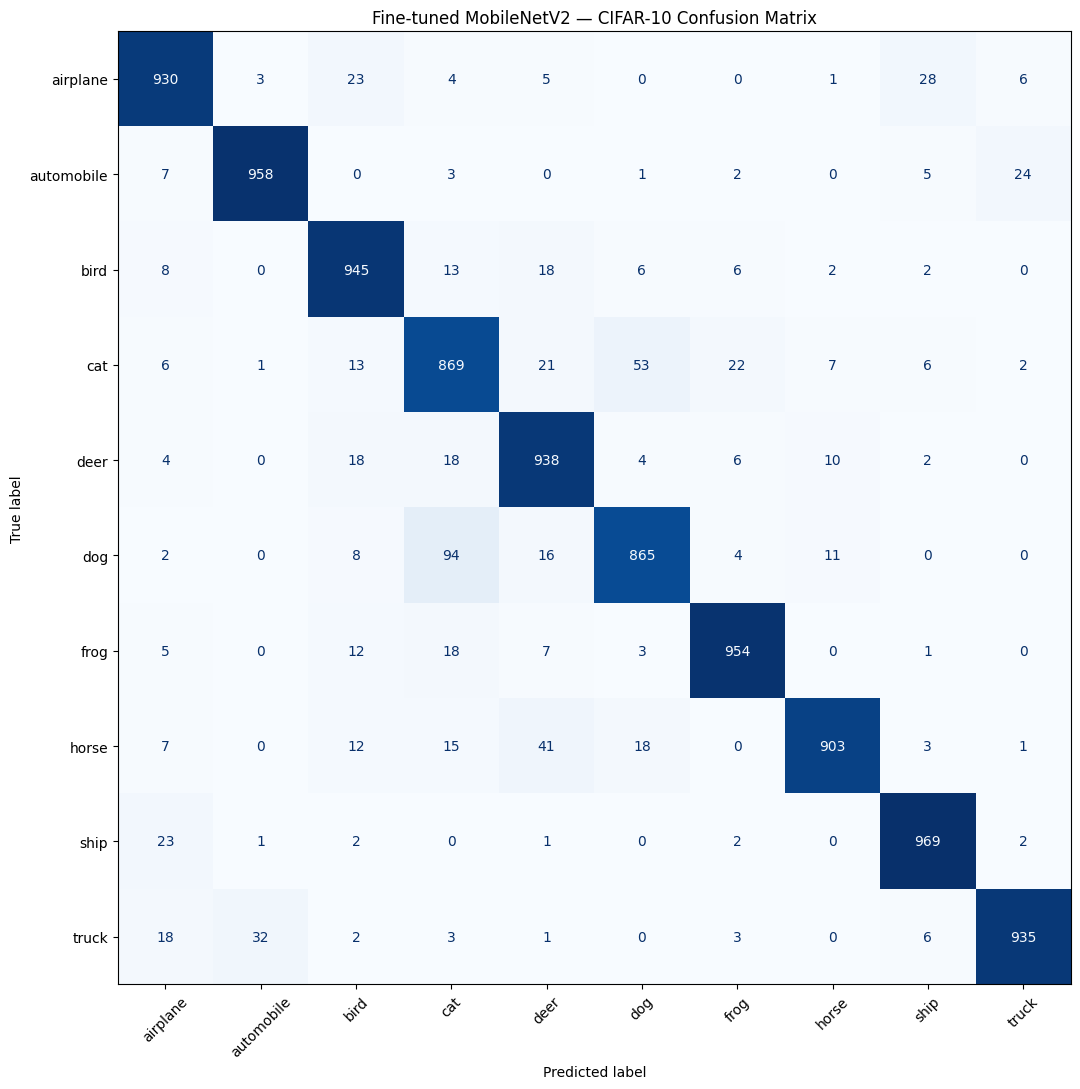

In [31]:
cm = confusion_matrix(
    y_true,
    y_pred_ft,
    labels=np.arange(10)
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(11, 11))

display_cm.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title("Fine-tuned MobileNetV2 — CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

## Part 7: Final Report

In [32]:
best_model = comparison.iloc[0]["Model"]

accuracy_gain = (test_accuracy_ft - test_accuracy_tl) * 100

report = f"""
CIFAR-10 Image Classification:
CNN from Scratch vs Transfer Learning

1. Objective
The objective was to compare a custom CNN trained from scratch
with transfer learning using pretrained MobileNetV2.

2. Dataset
CIFAR-10 contains 60,000 RGB images across 10 classes.
The images have a resolution of 32x32 pixels.
We used 45,000 images for training, 5,000 for validation,
and 10,000 for final testing.

3. Models
A. Custom CNN:
Three convolutional blocks followed by global average pooling,
a dense layer, dropout, and a 10-class softmax output.

B. Frozen MobileNetV2:
ImageNet-pretrained MobileNetV2 used as a frozen feature extractor.
Only the newly added classification head was trained.

C. Fine-tuned MobileNetV2:
Selected upper layers were unfrozen and adapted to CIFAR-10
using a smaller learning rate, while Batch Normalization
layers remained frozen.

4. Results
Custom CNN test accuracy: {test_accuracy_cnn * 100:.2f}%
Frozen MobileNetV2 test accuracy: {test_accuracy_tl * 100:.2f}%
Fine-tuned MobileNetV2 test accuracy: {test_accuracy_ft * 100:.2f}%

Custom CNN test loss: {test_loss_cnn:.4f}
Frozen MobileNetV2 test loss: {test_loss_tl:.4f}
Fine-tuned MobileNetV2 test loss: {test_loss_ft:.4f}

Best-performing model by test accuracy: {best_model}

5. Discussion
Transfer learning reused visual features learned from ImageNet.
Freezing the pretrained base reduced the number of trainable
parameters. Fine-tuning allowed selected pretrained layers to
adapt to CIFAR-10 and improved the test accuracy by
{accuracy_gain:.2f} percentage points compared with the
frozen feature-extraction experiment.

6. Evaluation
We evaluated the models on the same held-out CIFAR-10 test set.
For the fine-tuned model, we also examined class-wise precision,
recall, F1-score, and the confusion matrix.

7. Conclusion
The experiments demonstrate the value of pretrained visual
features and fine-tuning for CIFAR-10 image classification.
The final choice should consider predictive performance,
training cost, and the assignment's computational constraints.
"""

print(report)


CIFAR-10 Image Classification:
CNN from Scratch vs Transfer Learning

1. Objective
The objective was to compare a custom CNN trained from scratch
with transfer learning using pretrained MobileNetV2.

2. Dataset
CIFAR-10 contains 60,000 RGB images across 10 classes.
The images have a resolution of 32x32 pixels.
We used 45,000 images for training, 5,000 for validation,
and 10,000 for final testing.

3. Models
A. Custom CNN:
Three convolutional blocks followed by global average pooling,
a dense layer, dropout, and a 10-class softmax output.

B. Frozen MobileNetV2:
ImageNet-pretrained MobileNetV2 used as a frozen feature extractor.
Only the newly added classification head was trained.

C. Fine-tuned MobileNetV2:
Selected upper layers were unfrozen and adapted to CIFAR-10
using a smaller learning rate, while Batch Normalization
layers remained frozen.

4. Results
Custom CNN test accuracy: 72.86%
Frozen MobileNetV2 test accuracy: 84.99%
Fine-tuned MobileNetV2 test accuracy: 92.66%

Custom C